# K-Mers Counting

In [9]:
from Bio import SeqIO
from collections import Counter

def count_kmers_per_genome(fasta_file, k):
    genome_kmers = {}

    for record in SeqIO.parse(fasta_file, "fasta"):
        seq = str(record.seq).upper()
        kmers = Counter()

        for i in range(len(seq) - k + 1):
            kmer = seq[i:i+k]
            if "N" not in kmer:
                kmers[kmer] += 1

        genome_kmers[(record.id).split('.')[0]] = kmers

    return genome_kmers


In [10]:
import os

fasta_path = "../data/data_fasta"
fasta_paths = os.listdir(fasta_path)
kmers_dict = {}
print(len(fasta_paths))
for fasta_file in fasta_paths:
    full_path = os.path.join(fasta_path, fasta_file)
    kmers_dict.update(count_kmers_per_genome(full_path, k=3))

2176


In [11]:
import pandas as pd

# 1. Create a DataFrame from the list of Counters
# This automatically aligns keys (k-mers) and fills missing ones with NaN
df = pd.DataFrame.from_records(list(kmers_dict.values())).fillna(0)

# 2. Sum columns (k-mers) and get top 20
top20_series = df.sum().nlargest(20)

# 3. Extract results
kmers = top20_series.index.tolist()
counts = top20_series.values.tolist()

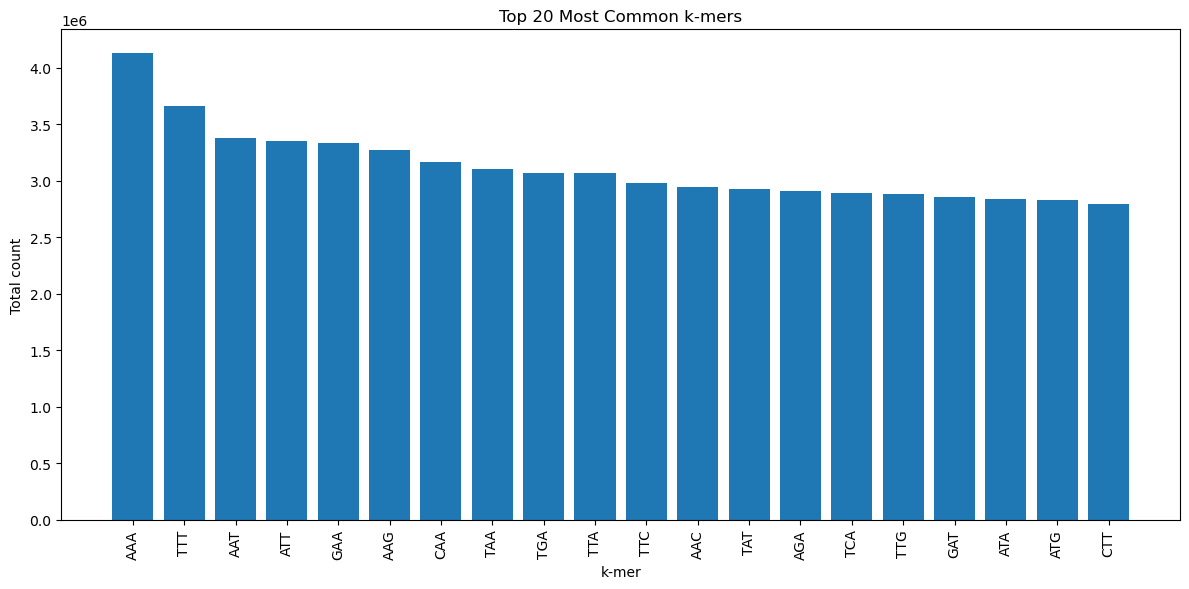

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.bar(kmers, counts)
plt.xticks(rotation=90)
plt.xlabel("k-mer")
plt.ylabel("Total count")
plt.title("Top 20 Most Common k-mers")
plt.tight_layout()
plt.show()


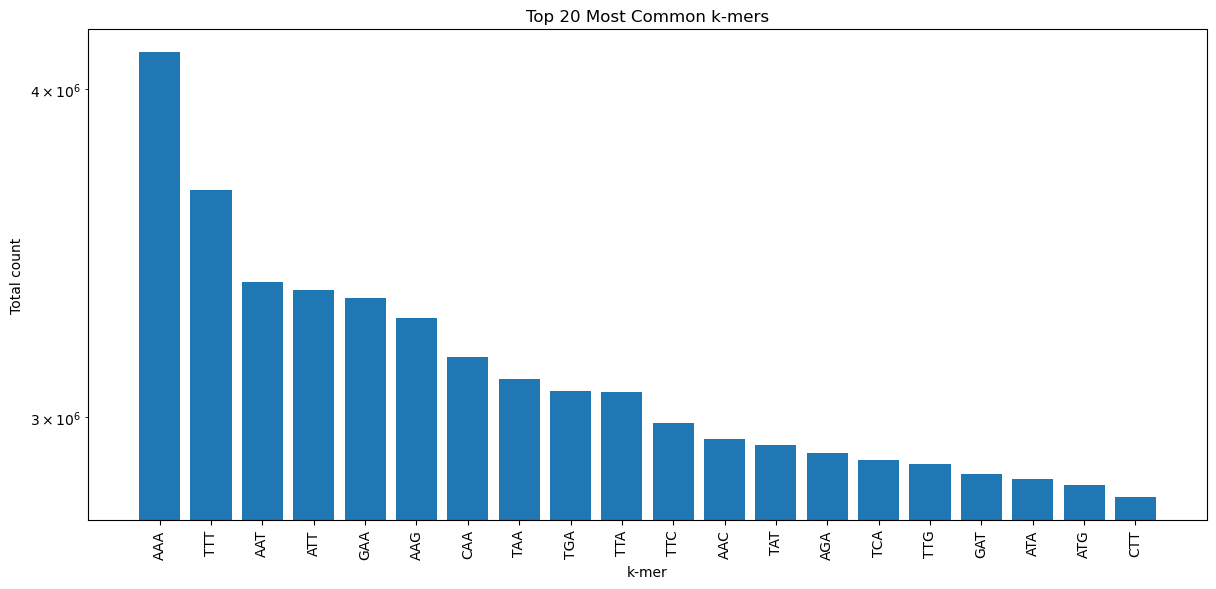

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.bar(kmers, counts)
plt.xticks(rotation=90)
plt.xlabel("k-mer")
plt.ylabel("Total count")
plt.title("Top 20 Most Common k-mers")
plt.tight_layout()
plt.yscale("log")
plt.show()

In [14]:
print(top20)

NameError: name 'top20' is not defined